# Data diagnostics

These are ex-post descriptive checks, not fitted preprocessing statistics. Core data validation rejects missing records and never fills them.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from risk_aware_portfolio.utils.config import load_config
from risk_aware_portfolio.utils.paths import resolve_path
config = load_config()
from risk_aware_portfolio.data.loader import load_panel
from risk_aware_portfolio.data.validation import validate_panel
from risk_aware_portfolio.data.universe import require_balanced_universe
alpha_path = config["data"]["alpha_path"]
panel = load_panel(resolve_path(config["data"]["input_path"]),
                   resolve_path(alpha_path) if alpha_path else None)
validate_panel(panel)
print("Assets:", len(require_balanced_universe(panel)))
display(panel.head())
display(panel.groupby("date").size().describe())


Assets: 60


,date,asset,return,alpha,market_cap,industry,size,value,momentum,volatility,liquidity
0,2020-01-02,asset_0000,0.003235,-0.496685,5.459725e+09,industry_0,0.420664,-0.590529,-1.767500,1.832282,0.421258
1,2020-01-02,asset_0001,0.013438,-1.904702,4.342394e+09,industry_1,0.191692,0.622188,-1.415450,-0.958320,0.899212
2,2020-01-02,asset_0002,0.002056,-1.388076,5.481484e+08,industry_2,-1.877943,0.582182,0.282775,-0.881411,-0.771717
3,2020-01-02,asset_0003,-0.006855,-0.409016,6.066982e+09,industry_3,0.526127,-0.421291,-0.109724,0.922397,0.411205
4,2020-01-02,asset_0004,-0.002596,3.085872,2.139089e+09,industry_0,-0.516354,1.164567,-1.107767,-1.078376,-0.365787


count    315.0
mean      60.0
std        0.0
min       60.0
25%       60.0
50%       60.0
75%       60.0
max       60.0
dtype: float64

Alpha scores at decision date t are compared with return at t+1. The following IC series is descriptive; it is never fed into historical portfolio weights.

,alpha_mode,mean,hac_standard_error,hac_t_stat,p_value
0,raw_ic,0.030064,0.010040,2.994462,0.002749
1,neutralized_ic,0.024970,0.006182,4.039170,0.000054


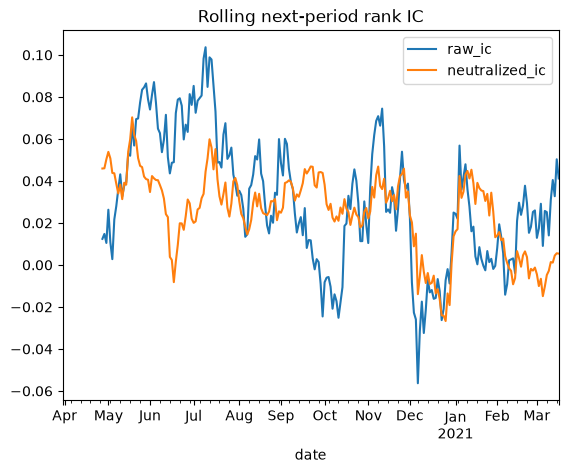

In [2]:
display(pd.read_csv(resolve_path("outputs/tables/alpha_ic_summary.csv")))
ic = pd.read_csv(resolve_path("outputs/tables/alpha_ic.csv"), parse_dates=["date"]).set_index("date")
ic.rolling(21).mean().plot(title="Rolling next-period rank IC");
